# Notebook 5 - Bivariate Analysis
Sprint 4 - EDA

Bivariate analysis studies the relationship between two variables. I look at three types of pairs: numerical vs numerical, numerical vs categorical and categorical vs categorical. Since my target is Churn, I pay special attention to how each variable relates to churn. A relationship found here is an observation only, it does not prove that one variable causes the other.

**Dataset:** Telco Customer Churn (Kaggle, 7043 rows and 21 columns)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

# working copy for analysis only
df_eda = df.copy()
df_eda["TotalCharges"] = pd.to_numeric(df_eda["TotalCharges"], errors="coerce")

# numeric version of the target (1 = churned) so that the average gives the churn rate
df_eda["Churn_num"] = (df_eda["Churn"] == "Yes").astype(int)

num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
cat_cols = [c for c in df.columns if c not in num_cols + ["customerID", "Churn"]]

print("Overall churn rate:", round(df_eda["Churn_num"].mean() * 100, 1), "%")

Overall churn rate: 26.5 %


I made a numeric copy of the target called Churn_num (1 for Yes, 0 for No). The mean of this column is the churn rate, which makes it easy to compare groups.

# Part 1 - Numerical vs Numerical

## 1.1 Scatter Plot

**Concept:** A scatter plot puts one numerical variable on the x axis and another on the y axis, and each row is one point. It shows the direction (upward or downward), the strength (tight or scattered) and the shape (straight or curved) of the relationship, and also unusual points.

**Example (business):** Plotting advertising spend against sales for 50 months. If the points rise from left to right in a tight band, higher spending goes with higher sales. If the points look like a random cloud, there is no relationship.

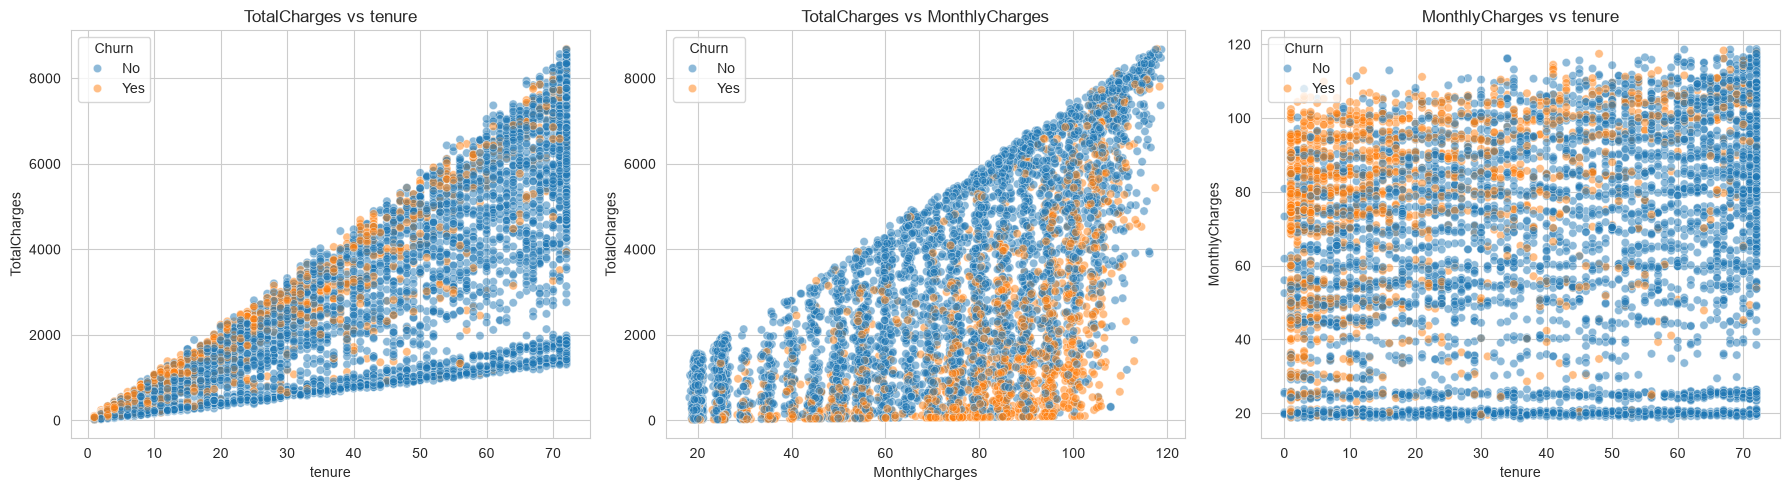

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

pairs = [("tenure", "TotalCharges"), ("MonthlyCharges", "TotalCharges"), ("tenure", "MonthlyCharges")]

for ax, (x, y) in zip(axes, pairs):
    sns.scatterplot(data=df_eda, x=x, y=y, hue="Churn", alpha=0.5, ax=ax)
    ax.set_title(y + " vs " + x)

plt.tight_layout()
plt.show()

**What the code does:** It draws three scatter plots, one for each pair of numerical columns, and colors each customer by Churn.

**Why this method was used:** A scatter plot is the natural plot for two numerical variables. The color by Churn lets me see the target at the same time without making another plot.

**What the output means:** In tenure vs TotalCharges the points rise from left to right in a wide fan shape. In MonthlyCharges vs TotalCharges the points also rise but are more spread. In tenure vs MonthlyCharges the points form a cloud with no clear direction. In the first plot the churned customers are concentrated at the lower left, which is short tenure and low total charges.

**Insights:** TotalCharges grows with tenure, which is logical because total charges are roughly monthly charges multiplied by the number of months. The fan shape appears because customers with the same tenure pay different monthly prices. Tenure and monthly charges are almost unrelated to each other. Customers who churn tend to be new customers.

**Effect on the ML pipeline:** TotalCharges carries a lot of the same information as tenure and MonthlyCharges, so it can cause redundancy (multicollinearity) in linear models. I will measure this in the next section and in the multivariate notebook.

## 1.2 Correlation Coefficient

**Concept:** The Pearson correlation coefficient gives the strength of a straight line relationship between two numerical variables as a number between -1 and +1. A value near +1 means that both increase together, near -1 means that one increases while the other decreases, and near 0 means no straight line relationship. Correlation does not prove causation.

**Example (numerical):** Ice cream sales and temperature have a high positive correlation, because both rise in summer. But ice cream sales and swimming pool accidents also correlate, and ice cream does not cause accidents, since the hidden cause is hot weather.

In [3]:
corr = df_eda[num_cols].corr()
print(corr.round(2))
print()

# correlation of each numerical column with the numeric target
print(df_eda[num_cols + ["Churn_num"]].corr()["Churn_num"].drop("Churn_num").round(2))

                tenure  MonthlyCharges  TotalCharges
tenure            1.00            0.25          0.83
MonthlyCharges    0.25            1.00          0.65
TotalCharges      0.83            0.65          1.00

tenure           -0.35
MonthlyCharges    0.19
TotalCharges     -0.20
Name: Churn_num, dtype: float64


**What the code does:** `corr()` calculates the Pearson correlation between every pair of numerical columns. The second part takes only the correlation of each numerical column with the numeric churn column.

**Why this method was used:** A number is easier to compare than a plot, and the correlation with the target shows which numerical features are linked to churn.

**What the output means:** Tenure and TotalCharges have a strong positive correlation of about 0.83. MonthlyCharges and TotalCharges have a moderate positive correlation of about 0.65. Tenure and MonthlyCharges have a weak positive correlation of about 0.25. With churn, tenure has a moderate negative correlation of about -0.35, TotalCharges has about -0.20 and MonthlyCharges has a weak positive correlation of about 0.19.

**Insights:** Customers with longer tenure churn less, and customers with higher monthly bills churn a bit more. TotalCharges looks protective against churn only because it grows with tenure. So its link with churn is mostly the effect of tenure. The two strong relationships between tenure, MonthlyCharges and TotalCharges are an arithmetic result of how the total is built.

**Effect on the ML pipeline:** Tenure and TotalCharges are highly correlated, so keeping both can cause multicollinearity for linear or logistic regression. Options are to drop one, combine them, or use a tree based model, which handles correlated features better. Tenure is likely to be an important predictor.

# Part 2 - Numerical vs Categorical

## 2.1 Group Summary (groupby)

**Concept:** To compare a numerical variable across the categories of another variable, I split the rows into groups with `groupby` and calculate a summary like the mean and median of each group.

**Example (business):** The average salary of each department. If Engineering has an average of 90k and Support has 45k, the department clearly relates to salary.

In [4]:
for col in num_cols:
    print(col)
    print(df_eda.groupby("Churn")[col].agg(["mean", "median", "std"]).round(2))
    print()

tenure
        mean  median    std
Churn                      
No     37.57    38.0  24.11
Yes    17.98    10.0  19.53

MonthlyCharges
        mean  median    std
Churn                      
No     61.27   64.43  31.09
Yes    74.44   79.65  24.67

TotalCharges
          mean   median      std
Churn                           
No     2555.34  1683.60  2329.46
Yes    1531.80   703.55  1890.82



**What the code does:** It groups the customers by Churn and calculates the mean, median and standard deviation of each numerical column for the two groups.

**Why this method was used:** A group summary gives exact numbers for the comparison, and using the median as well as the mean protects me from being misled by skew.

**What the output means:** Customers who churned have a mean tenure of about 18 months, against about 37 months for customers who stayed. Their mean MonthlyCharges is about 74, against about 61. Their mean TotalCharges is about 1532, against about 2555.

**Insights:** Churned customers are newer and pay higher monthly bills. The difference in tenure is large, about half. The lower TotalCharges of churned customers is mostly because they stayed for fewer months.

**Effect on the ML pipeline:** Tenure and MonthlyCharges clearly differ between the two classes, so they are good candidates as features. A large difference between group means is a sign that the feature can help to separate the classes.

## 2.2 Box Plot

**Concept:** A box plot split by category draws one box per group, so the medians, spreads and outliers of the groups can be compared side by side.

**Example (business):** Comparing delivery times of three courier companies with three boxes shows which one is fastest on average and which one is most inconsistent.

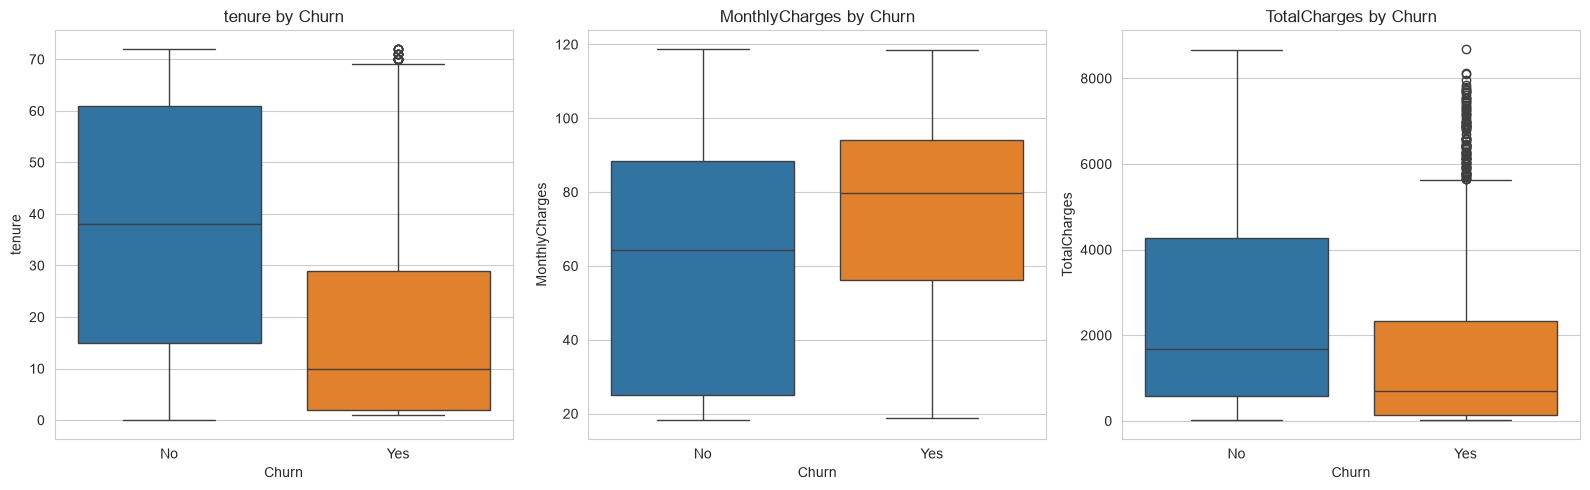

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, col in zip(axes, num_cols):
    sns.boxplot(data=df_eda, x="Churn", y=col, hue="Churn", legend=False, ax=ax)
    ax.set_title(col + " by Churn")

plt.tight_layout()
plt.show()

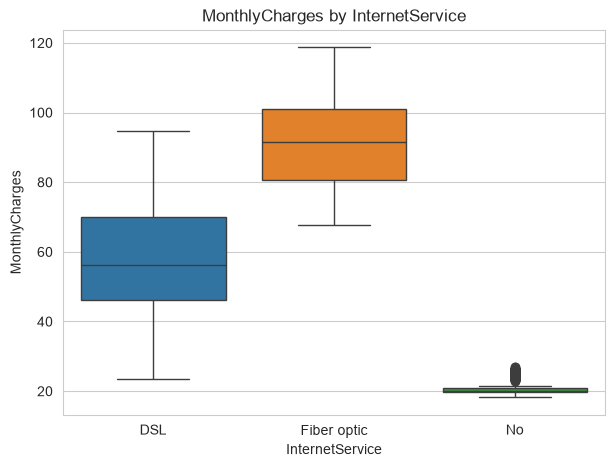

                 mean  median   min    max
InternetService                           
DSL              58.1    56.2  23.4   94.8
Fiber optic      91.5    91.7  67.8  118.8
No               21.1    20.2  18.2   26.9


In [6]:
# MonthlyCharges by InternetService, to explain the spike seen in the univariate notebook
plt.figure(figsize=(7, 5))
sns.boxplot(data=df_eda, x="InternetService", y="MonthlyCharges", hue="InternetService", legend=False)
plt.title("MonthlyCharges by InternetService")
plt.show()

print(df_eda.groupby("InternetService")["MonthlyCharges"].agg(["mean", "median", "min", "max"]).round(1))

**What the code does:** The first cell draws box plots of each numerical column for churned and not churned customers. The second cell compares MonthlyCharges across the three internet service types and prints the group statistics.

**Why this method was used:** Box plots put the two groups side by side so the shift in the median and the spread is easy to see. The second plot tests an idea from the univariate notebook, where I saw a spike of low monthly charges.

**What the output means:** The median tenure box of the churned group is much lower than for the group that stayed. The median MonthlyCharges is higher for the churned group. For MonthlyCharges by InternetService the customers with no internet pay about 21 on average, DSL customers about 58 and fiber optic customers about 91.

**Insights:** This explains the spike near 20 in MonthlyCharges, because those are customers with no internet service. Fiber customers pay the most and, as seen in the univariate notebook, they are also the largest churn risk group, so a part of the link between high charges and churn may come from the fiber optic service.

**Effect on the ML pipeline:** InternetService and MonthlyCharges are related to each other, so they partly carry the same information. This is a feature interaction that the model can use, and it is a reason to be careful when reading feature importance.

## 2.3 Violin Plot

**Concept:** A violin plot combines a box plot with a KDE. The width of the shape at each height shows how many values are there, so it shows the whole distribution of each group, including whether it has more than one peak.

**Example (AI/ML):** Two groups can have the same median and the same box plot, but one group can have two clusters. A violin plot shows the two clusters, while a box plot hides them.

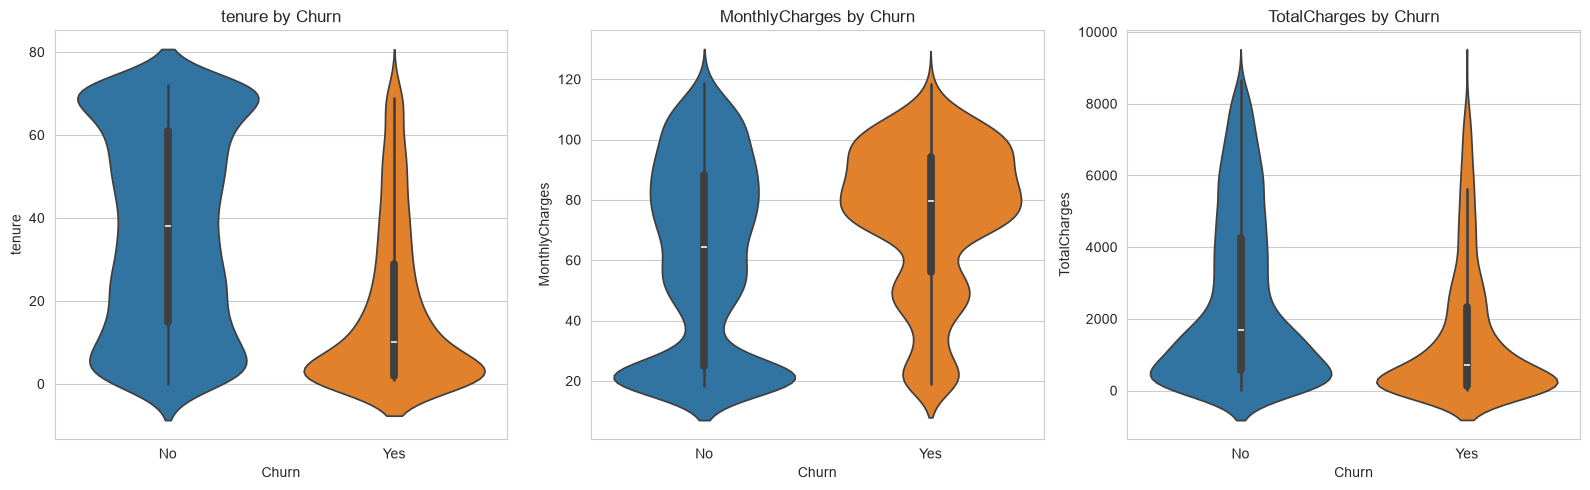

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, col in zip(axes, num_cols):
    sns.violinplot(data=df_eda, x="Churn", y=col, hue="Churn", legend=False, ax=ax)
    ax.set_title(col + " by Churn")

plt.tight_layout()
plt.show()

**What the code does:** It draws violin plots of the three numerical columns for the two Churn groups.

**Why this method was used:** The box plot shows only five numbers, but the violin plot shows the full shape of the distribution of each group, so I can check differences that a box hides.

**What the output means:** For tenure, the not churned group has a wide part at both the bottom and the top, while the churned group is concentrated at the bottom. For MonthlyCharges, the churned group is concentrated at the higher values, and the not churned group has a wide part near the low charges. For TotalCharges both groups are concentrated at the bottom, but the churned group is more concentrated.

**Insights:** Customers who stay include a large group of very loyal customers with a tenure near 72 months, while churn mostly happens in the first months. The not churned group contains the low paying customers without internet, who rarely churn.

**Effect on the ML pipeline:** The shape differences between the groups show that the features carry class information. Non-linear models such as trees can use these shape differences better than a simple linear model.

# Part 3 - Categorical vs Categorical

## 3.1 Cross Tabulation

**Concept:** A cross tabulation (contingency table) counts how many rows fall in each combination of two categorical variables. Converting the counts to percentages of each row gives the share of each outcome within each group, which makes groups of different sizes comparable.

**Example (business):** A table of product category against payment method shows how many orders of each category were paid by card, UPI or cash. In percent form it shows which category depends more on a payment type.

In [8]:
# counts
print(pd.crosstab(df["Contract"], df["Churn"]))
print()

# percentage within each contract type (rows add up to 100)
print((pd.crosstab(df["Contract"], df["Churn"], normalize="index") * 100).round(1))

Churn             No   Yes
Contract                  
Month-to-month  2220  1655
One year        1307   166
Two year        1647    48

Churn             No   Yes
Contract                  
Month-to-month  57.3  42.7
One year        88.7  11.3
Two year        97.2   2.8


**What the code does:** `pd.crosstab` counts customers for every combination of Contract and Churn. With `normalize=index` each row is converted to percentages, so every contract type adds up to 100.

**Why this method was used:** Raw counts are misleading when groups have different sizes, because the biggest group will always have the most churners. Row percentages compare the churn rate fairly.

**What the output means:** Month-to-month customers churn at about 42.7%, one year contract customers at about 11.3% and two year customers at about 2.8%.

**Insights:** Contract type has a very strong relationship with churn. Customers without a long contract are about 15 times more likely to churn than two year customers. A longer contract may be locking customers in, or customers who are loyal may choose long contracts, so the cause cannot be proven from this table alone.

**Effect on the ML pipeline:** Contract is likely to be one of the strongest features of the model. It is categorical with an order (month-to-month, one year, two year), so ordinal encoding may be considered.

## 3.2 Grouped Bar Chart

**Concept:** A grouped bar chart shows, for each category of one variable, separate bars for the categories of a second variable. A version that shows percentages (the churn rate) makes the relationship easy to see.

**Example (business):** A bar chart of the number of orders per product category, with one bar for each region, shows both which categories are large and which regions drive them.

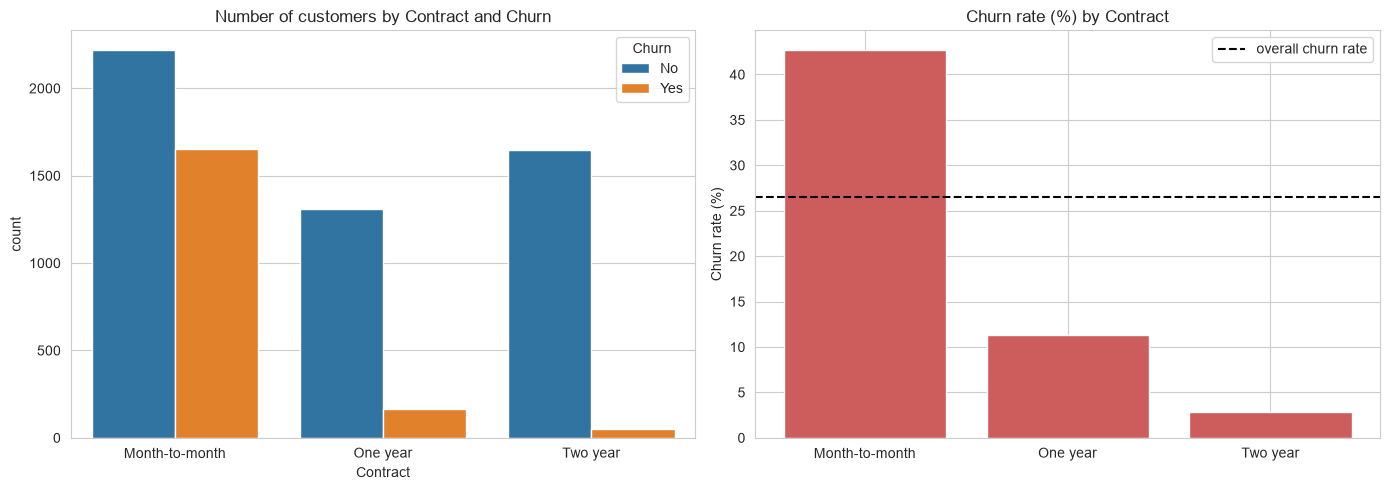

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# counts
sns.countplot(data=df, x="Contract", hue="Churn", ax=axes[0])
axes[0].set_title("Number of customers by Contract and Churn")

# churn rate
rate = df_eda.groupby("Contract")["Churn_num"].mean() * 100
axes[1].bar(rate.index, rate.values, color="indianred")
axes[1].axhline(df_eda["Churn_num"].mean() * 100, color="black", linestyle="--", label="overall churn rate")
axes[1].set_title("Churn rate (%) by Contract")
axes[1].set_ylabel("Churn rate (%)")
axes[1].legend()

plt.tight_layout()
plt.show()

**What the code does:** The left plot is a grouped bar chart of customer counts for each Contract and Churn combination. The right plot shows the churn rate of each contract type, with a dashed line at the overall churn rate.

**Why this method was used:** The count plot shows the size of the groups and the rate plot shows the risk of each group. Having both prevents a wrong conclusion from either one alone.

**What the output means:** In the left plot the Month-to-month group is the largest and also has the biggest Yes bar. In the right plot the month-to-month rate is far above the dashed line, and the one year and two year rates are far below it.

**Insights:** Month-to-month customers are both the largest segment and the highest risk segment, so they are the main source of lost customers. Moving customers from month-to-month to longer contracts is a clear business opportunity.

**Effect on the ML pipeline:** The rate plot is a quick way to judge whether a categorical feature separates the classes, and I will use the same idea for the other columns below.

## 3.3 Churn rate across all categorical features

**Concept:** To find which categorical features relate most to the target, I calculate the churn rate of every category of every feature and compare them. A feature is useful when its categories have very different churn rates.

**Example (AI/ML):** In a loan dataset, if the default rate is 3% for salaried people and 20% for self employed people, employment type separates good and bad borrowers well, while a column where all groups default at about 8% does not.

In [10]:
rows = []
for col in cat_cols:
    rates = df_eda.groupby(col)["Churn_num"].mean() * 100
    counts = df_eda[col].value_counts()
    for category in rates.index:
        rows.append([col, category, counts[category], round(rates[category], 1)])

churn_rates = pd.DataFrame(rows, columns=["feature", "category", "customers", "churn_rate"])

print("Highest churn rate:")
print(churn_rates.sort_values("churn_rate", ascending=False).head(10).to_string(index=False))
print()
print("Lowest churn rate:")
print(churn_rates.sort_values("churn_rate").head(10).to_string(index=False))

Highest churn rate:
         feature         category  customers  churn_rate
   PaymentMethod Electronic check       2365        45.3
        Contract   Month-to-month       3875        42.7
 InternetService      Fiber optic       3096        41.9
  OnlineSecurity               No       3498        41.8
   SeniorCitizen                1       1142        41.7
     TechSupport               No       3473        41.6
    OnlineBackup               No       3088        39.9
DeviceProtection               No       3095        39.1
 StreamingMovies               No       2785        33.7
PaperlessBilling              Yes       4171        33.6

Lowest churn rate:
         feature            category  customers  churn_rate
        Contract            Two year       1695         2.8
 InternetService                  No       1526         7.4
    OnlineBackup No internet service       1526         7.4
DeviceProtection No internet service       1526         7.4
     TechSupport No internet serv

In [11]:
# difference between the best and worst category of each feature
spread = churn_rates.groupby("feature")["churn_rate"].agg(lambda s: s.max() - s.min()).sort_values(ascending=False)
spread.round(1)

feature
Contract            39.9
InternetService     34.5
OnlineSecurity      34.4
TechSupport         34.2
OnlineBackup        32.5
DeviceProtection    31.7
PaymentMethod       30.1
StreamingMovies     26.3
StreamingTV         26.1
SeniorCitizen       18.1
PaperlessBilling    17.3
Dependents          15.8
Partner             13.3
MultipleLines        3.7
PhoneService         1.8
gender               0.7
Name: churn_rate, dtype: float64

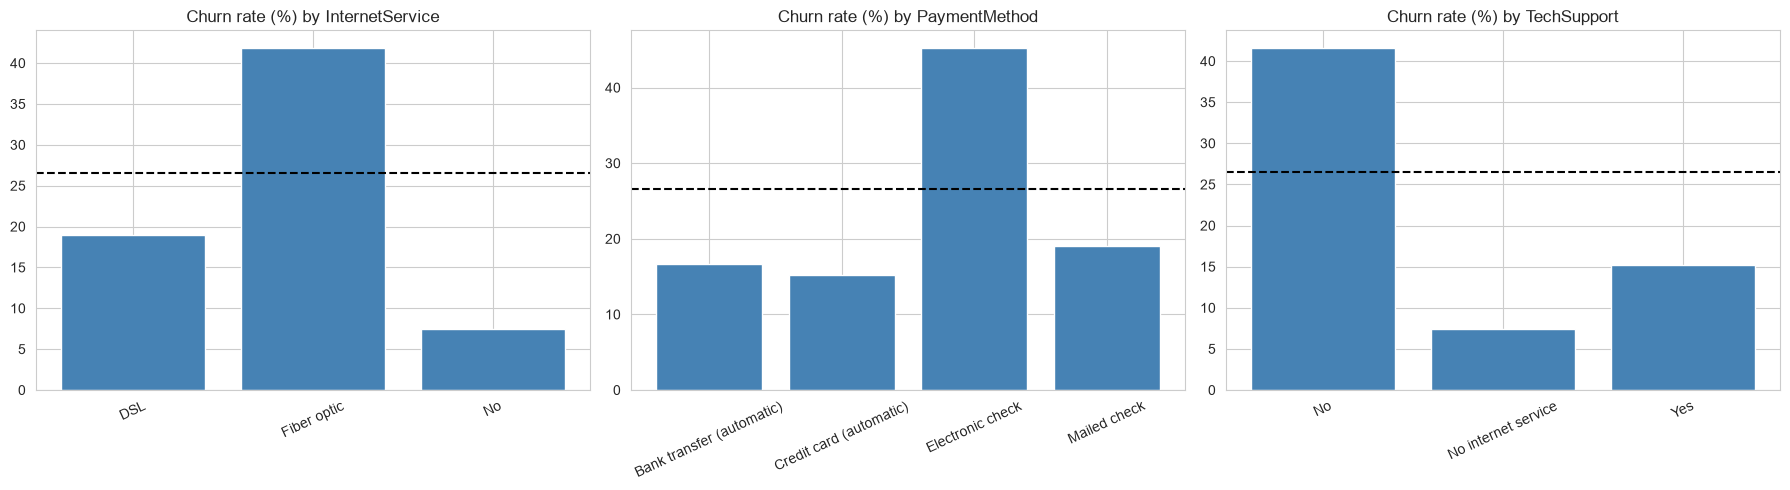

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, col in zip(axes, ["InternetService", "PaymentMethod", "TechSupport"]):
    rate = df_eda.groupby(col)["Churn_num"].mean() * 100
    ax.bar(rate.index, rate.values, color="steelblue")
    ax.axhline(df_eda["Churn_num"].mean() * 100, color="black", linestyle="--")
    ax.set_title("Churn rate (%) by " + col)
    ax.tick_params(axis="x", rotation=25)

plt.tight_layout()
plt.show()

**What the code does:** The first cell goes through every categorical feature, calculates the churn rate and the number of customers of each category, and prints the highest and lowest ten. The second cell measures the gap between the best and worst category of each feature. The third cell plots the churn rate for three important features with a dashed line at the overall rate.

**Why this method was used:** Doing it in a loop compares all features on the same basis, and the gap gives a simple ranking of how much a feature separates churners from non churners.

**What the output means:** The highest churn rates are for month-to-month contracts (about 43%), electronic check payments (about 45%), fiber optic internet (about 42%), customers without online security or tech support (about 42%) and senior citizens (about 42%). The lowest rates are for two year contracts (about 3%), customers with no internet service (about 7%) and one year contracts (about 11%). Gender has almost no gap, with about 27% for females and 26% for males.

**Insights:** Contract, online security, tech support, internet service and payment method show large gaps, so they look informative. Gender and PhoneService show almost no difference. Customers with no add-on support services churn much more than customers with them, which suggests that bundling security and support services could improve retention. Electronic check users churn far more than customers on automatic payments, which may point to a payment friction or engagement problem.

**Effect on the ML pipeline:** The features with large gaps are strong candidates for the model, and features with almost no gap could be dropped or tested for usefulness during feature selection. This is also a first sketch of what a model will learn, so it can be used to check the model later.

# Part 4 - Findings

| Pair | Relationship observed |
|---|---|
| tenure vs TotalCharges | Strong positive correlation of about 0.83, because the total is built from months and price |
| MonthlyCharges vs TotalCharges | Moderate positive correlation of about 0.65 |
| tenure vs MonthlyCharges | Weak correlation of about 0.25 |
| tenure vs Churn | Churned customers have about half the tenure of the others, so churn happens early |
| MonthlyCharges vs Churn | Churned customers pay more per month on average |
| MonthlyCharges vs InternetService | No internet is about 21, DSL about 58, fiber about 91 |
| Contract vs Churn | Month-to-month about 43%, one year about 11%, two year about 3% |
| InternetService vs Churn | Fiber optic is about 42%, DSL about 19%, none about 7% |
| PaymentMethod vs Churn | Electronic check is about 45%, others between 15% and 19% |
| TechSupport and OnlineSecurity vs Churn | Customers without them churn at about 42%, with them about 15% |
| gender vs Churn | No real difference |

# Summary

- Tenure is the strongest numerical feature related to churn, and customers leave mostly in the early months.
- Contract type is the strongest categorical feature, followed by internet service, support services and payment method.
- Fiber optic customers pay the most and churn the most, so the service type, the price and churn are tied together.
- Gender and phone service show almost no relationship with churn.
- TotalCharges is strongly related to tenure, so there is a multicollinearity risk.

**Points for later sprints**
1. Check multicollinearity between tenure, MonthlyCharges and TotalCharges (next notebook).
2. Consider tenure bands as a feature.
3. Consider dropping or testing weak features such as gender.
4. Use the strong categorical features carefully in encoding, for example ordinal encoding for Contract.
5. Remember that these are relationships and not proof of cause.

**What I learned:** Counts alone can mislead, because the largest group always has the most churners. Comparing churn rates within each group, which is a row percentage, is the fair way to compare. I also learned that a strong relation, like TotalCharges and churn, can come from another variable, tenure.

Next: `06_Multivariate_Analysis.ipynb`